# Русские блины: рабочее место аналитика

**Учебные синтетические данные, не данные заказчика.** Одна точка, десять блюд,
шесть месяцев. Снимок на конец 30.09.2026; прогноз 01–07.10.2026.
Все прогнозы, проверки и закупки вызывают функции пакета `blini`.
Изменяйте основной модуль, а затем запускайте ноутбук заново.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'src' / 'blini').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'blini').exists(), 'Откройте ноутбук из корня проекта или notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
from blini.config import Config
from blini.data import load_csv_directory, validate_data
from blini.demo import AS_OF, SCENARIOS, generate_demo
from blini.service import run_pipeline
from blini.inventory import ingredient_demand

if not (ROOT / 'data' / 'demo' / 'normal').exists():
    generate_demo(ROOT / 'data' / 'demo')
config = Config.load(ROOT / 'config' / 'default.json')
raw = load_csv_directory(ROOT / 'data' / 'demo' / 'normal')


## 1. Проверка загрузки

Ошибки блокируют расчёт. Предупреждения о пропущенных продажах и отсутствии
сведений о стоп-листах нужно проверить отдельно. Отсутствующий факт не равен нулю.


In [2]:
validation = validate_data(raw, AS_OF)
print('Ошибки:', validation.errors)
print('Предупреждения:')
for warning in validation.warnings:
    print('-', warning)
tables = validation.require_valid()
display(pd.DataFrame({'table': list(tables), 'rows': [len(df) for df in tables.values()]}))
display(tables['recipes'].head())


Ошибки: []
Предупреждения:
- Нет сведений об отсутствии товара: наблюдаемые продажи могут быть ниже реального спроса. Данные о потерянных продажах нужны для коррекции.


,table,rows
0,sales,1830
1,dishes,10
2,ingredients,13
3,recipes,49
4,stock,26
5,deliveries,13
6,purchase_params,13
7,calendar,275


,dish_id,ingredient_id,quantity,unit
0,D01,I01,0.045,kg
1,D01,I02,0.080,l
2,D01,I03,0.200,pcs
3,D01,I04,0.008,kg
4,D02,I01,0.045,kg


## 2. Продажи по дням недели

Сравним обычный режим и специально усиленные выходные. Группировка здесь —
исследование фактов; прогноз далее рассчитывается только основным модулем.


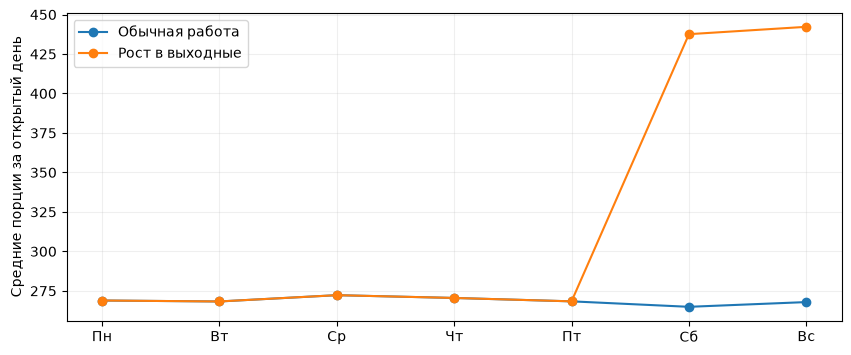

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
for scenario, label in [('normal', 'Обычная работа'), ('weekend_growth', 'Рост в выходные')]:
    source = validate_data(load_csv_directory(ROOT / 'data' / 'demo' / scenario), AS_OF).require_valid()
    daily = source['sales'].groupby('date').quantity.sum()
    by_weekday = daily.groupby(daily.index.dayofweek).mean().reindex(range(7))
    ax.plot(range(7), by_weekday, 'o-', label=label)
ax.set_xticks(range(7), ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
ax.set_ylabel('Средние порции за открытый день'); ax.legend(); ax.grid(alpha=.2)
plt.show()


## 3. Сравнение алгоритмов и выбранный прогноз

Три последовательных недельных блока; обучение каждого блока только до origin.
MAE — в порциях, WAPE — доля, NaN при нулевом знаменателе. Методы сравниваются
на одинаковом наборе известных дат, покрытие отражено в n и folds.
Выбор по pooled MAE; эти же отрезки не являются независимым финальным тестом.


,method,mae,wape,n,folds,store_id,dish_id
1,weekday_mean,2.869048,0.174638,21,3,S01,D01
0,seasonal_naive,4.047619,0.246377,21,3,S01,D01
3,weekday_mean,3.309524,0.176845,21,3,S01,D02
2,seasonal_naive,4.190476,0.223919,21,3,S01,D02
5,weekday_mean,2.214286,0.104730,21,3,S01,D03
4,seasonal_naive,3.238095,0.153153,21,3,S01,D03
7,weekday_mean,3.250000,0.135149,21,3,S01,D04
6,seasonal_naive,4.904762,0.203960,21,3,S01,D04
9,weekday_mean,2.452381,0.095725,21,3,S01,D05
8,seasonal_naive,3.000000,0.117100,21,3,S01,D05


,dish_id,method,explanation
0,D01,weekday_mean,"Минимальный MAE=2.869 на 21 общих наблюдениях,..."
7,D02,weekday_mean,"Минимальный MAE=3.310 на 21 общих наблюдениях,..."
14,D03,weekday_mean,"Минимальный MAE=2.214 на 21 общих наблюдениях,..."
21,D04,weekday_mean,"Минимальный MAE=3.250 на 21 общих наблюдениях,..."
28,D05,weekday_mean,"Минимальный MAE=2.452 на 21 общих наблюдениях,..."
35,D06,weekday_mean,"Минимальный MAE=2.619 на 21 общих наблюдениях,..."
42,D07,weekday_mean,"Минимальный MAE=2.798 на 21 общих наблюдениях,..."
49,D08,seasonal_naive,"Минимальный MAE=2.667 на 21 общих наблюдениях,..."
56,D09,weekday_mean,"Минимальный MAE=2.119 на 21 общих наблюдениях,..."
63,D10,weekday_mean,"Минимальный MAE=2.488 на 21 общих наблюдениях,..."


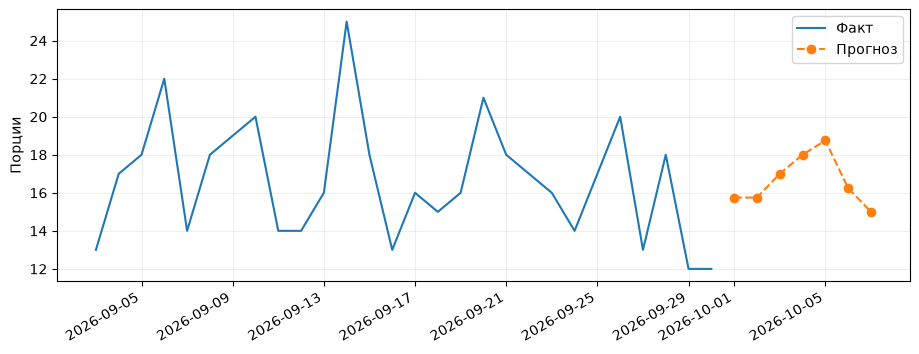

In [4]:
report = run_pipeline(raw, AS_OF, config)
display(report.metrics.sort_values(['dish_id', 'mae']))
display(report.forecast[['dish_id', 'method', 'explanation']].drop_duplicates())
dish_id = 'D01'
history = tables['sales'].query('dish_id == @dish_id').set_index('date').quantity.tail(28)
prediction = report.forecast.query('dish_id == @dish_id').set_index('date').quantity
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(history.index, history, label='Факт')
ax.plot(prediction.index, prediction, 'o--', label='Прогноз')
ax.set_ylabel('Порции'); ax.legend(); ax.grid(alpha=.2); fig.autofmt_xdate()
plt.show()


## 4. Дневные ошибки и даты обучения

Выгрузка ошибок позволяет проверить origin, календарный контрольный блок и
отсутствие будущих фактов в обучении. eligible=False исключён из выбора.


,origin,date,method,actual,predicted,absolute_error,eligible,store_id,dish_id
155,2026-09-23,2026-09-25,seasonal_naive,29.0,17.00,12.00,True,S01,D04
258,2026-09-09,2026-09-16,seasonal_naive,28.0,39.00,11.00,True,S01,D07
4,2026-09-09,2026-09-14,seasonal_naive,25.0,14.00,11.00,True,S01,D01
75,2026-09-23,2026-09-29,seasonal_naive,14.0,24.00,10.00,True,S01,D02
321,2026-09-16,2026-09-23,weekday_mean,39.0,29.50,9.50,True,S01,D08
259,2026-09-09,2026-09-10,weekday_mean,23.0,32.25,9.25,True,S01,D07
215,2026-09-09,2026-09-15,seasonal_naive,23.0,32.00,9.00,True,S01,D06
61,2026-09-16,2026-09-22,seasonal_naive,24.0,15.00,9.00,True,S01,D02
58,2026-09-16,2026-09-19,seasonal_naive,13.0,22.00,9.00,True,S01,D02
100,2026-09-16,2026-09-19,seasonal_naive,24.0,15.00,9.00,True,S01,D03


n       mae
method         origin                  
seasonal_naive 2026-09-09  70  3.314286
               2026-09-16  70  3.614286
               2026-09-23  70  3.442857
weekday_mean   2026-09-09  70  2.814286
               2026-09-16  70  2.721429
               2026-09-23  70  2.685714

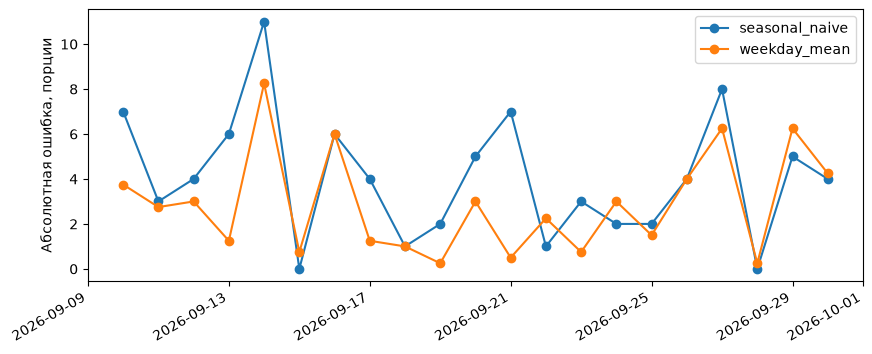

In [5]:
errors = report.errors
assert (errors.origin < errors.date).all()
display(errors.sort_values('absolute_error', ascending=False).head(15))
display(errors.groupby(['method', 'origin']).agg(n=('eligible', 'sum'), mae=('absolute_error', 'mean')))
fig, ax = plt.subplots(figsize=(10, 4))
for method, group in errors.query('dish_id == @dish_id and eligible').groupby('method'):
    ax.plot(group.date, group.absolute_error, 'o-', label=method)
ax.set_ylabel('Абсолютная ошибка, порции'); ax.legend(); fig.autofmt_xdate()
plt.show()


## 5. Одно блюдо и его ингредиенты

Проверяем пересчёт порций на ингредиенты **основной функцией**. Закупки общих
ингредиентов ниже рассчитаны на все блюда: вклад одного блюда показан отдельно,
его нельзя ошибочно считать всей потребностью точки.


In [6]:
one_forecast = report.forecast.query('dish_id == @dish_id')
one_recipe = tables['recipes'].query('dish_id == @dish_id')
display(one_recipe.merge(tables['ingredients'], on='ingredient_id'))
one_demand = ingredient_demand(one_forecast, one_recipe)
display(one_demand)
ingredient_ids = one_recipe.ingredient_id.tolist()
display(report.demand.query('ingredient_id in @ingredient_ids'))
display(report.recommendations.query('ingredient_id in @ingredient_ids')[
    ['ingredient', 'unit', 'forecast_demand', 'usable_stock', 'scheduled_deliveries',
     'safety_stock', 'order_quantity', 'order_date', 'arrival_date', 'warning']])
for row in report.recommendations.query('ingredient_id in @ingredient_ids').itertuples():
    print('\n', row.ingredient, ':', row.explanation)
    if row.warning: print('ВНИМАНИЕ:', row.warning)
display(report.inventory_log.query("ingredient_id == 'I01'"))


,dish_id,ingredient_id,quantity,unit,name,base_unit
0,D01,I01,0.045,kg,Мука,kg
1,D01,I02,0.080,l,Молоко,l
2,D01,I03,0.200,pcs,Яйцо,pcs
3,D01,I04,0.008,kg,Масло,kg


,date,store_id,ingredient_id,quantity
0,2026-10-01,S01,I01,0.70875
1,2026-10-01,S01,I02,1.26000
2,2026-10-01,S01,I03,3.15000
3,2026-10-01,S01,I04,0.12600
4,2026-10-02,S01,I01,0.70875
5,2026-10-02,S01,I02,1.26000
6,2026-10-02,S01,I03,3.15000
7,2026-10-02,S01,I04,0.12600
8,2026-10-03,S01,I01,0.76500
9,2026-10-03,S01,I02,1.36000


,date,store_id,ingredient_id,quantity
0,2026-10-01,S01,I01,11.82375
1,2026-10-01,S01,I02,21.02000
2,2026-10-01,S01,I03,52.55000
3,2026-10-01,S01,I04,2.10200
13,2026-10-02,S01,I01,11.90250
14,2026-10-02,S01,I02,21.16000
15,2026-10-02,S01,I03,52.90000
16,2026-10-02,S01,I04,2.11600
26,2026-10-03,S01,I01,11.50875
27,2026-10-03,S01,I02,20.46000


,ingredient,unit,forecast_demand,usable_stock,scheduled_deliveries,safety_stock,order_quantity,order_date,arrival_date,warning
0,Мука,kg,83.71125,48.3728,24.1864,12.556687,24.0,2026-10-01,2026-10-03,Упаковка/минимум создаёт излишек: в конце пери...
1,Молоко,l,148.82000,85.9960,42.9980,22.323000,43.0,2026-10-01,2026-10-03,
2,Яйцо,pcs,372.05000,214.9901,107.4951,55.807500,110.0,2026-10-01,2026-10-03,Упаковка/минимум создаёт излишек: в конце пери...
3,Масло,kg,14.88200,8.5996,4.2998,2.232300,4.5,2026-10-01,2026-10-03,Упаковка/минимум создаёт излишек: в конце пери...



 Мука : Период 2026-10-01–2026-10-07 (L=2, R=5). Потребность 83.711 kg; пригодный на первый день остаток 48.373, поставки в периоде 24.186. FEFO по дням: дефицит до поступления 0.000, после 11.152, пригодный на следующий день остаток без заказа 0.000. Упрощённый страховой запас 15% × 83.711 = 12.557. Нужно 11.152 + max(0, 12.557 − 0.000) = 23.709. С минимумом 0.5 и упаковкой 0.5: заказать 24.000 kg. Ранний дефицит считается потерянным спросом; поздний заказ его не компенсирует.
ВНИМАНИЕ: Упаковка/минимум создаёт излишек: в конце периода останется 12.848 kg новой партии, годна до 2026-11-01; дальнейший спрос не проверен, возможны списания.

 Молоко : Период 2026-10-01–2026-10-07 (L=2, R=5). Потребность 148.820 l; пригодный на первый день остаток 85.996, поставки в периоде 42.998. FEFO по дням: дефицит до поступления 0.000, после 19.826, пригодный на следующий день остаток без заказа 0.000. Упрощённый страховой запас 15% × 148.820 = 22.323. Нужно 19.826 + max(0, 22.323 − 0.000) = 42.149

,date,demand,arrivals,expired,expired_order,available_before,consumed,shortage,remaining,order_consumed,scenario,store_id,ingredient_id
0,2026-10-01,11.82375,0.0000,0.0,0.0,48.37280,11.82375,0.00000,36.54905,0.00000,baseline,S01,I01
1,2026-10-02,11.90250,0.0000,0.0,0.0,36.54905,11.90250,0.00000,24.64655,0.00000,baseline,S01,I01
2,2026-10-03,11.50875,24.1864,0.0,0.0,48.83295,11.50875,0.00000,37.32420,0.00000,baseline,S01,I01
3,2026-10-04,11.86875,0.0000,0.0,0.0,37.32420,11.86875,0.00000,25.45545,0.00000,baseline,S01,I01
4,2026-10-05,12.06000,0.0000,0.0,0.0,25.45545,12.06000,0.00000,13.39545,0.00000,baseline,S01,I01
5,2026-10-06,12.15000,0.0000,0.0,0.0,13.39545,12.15000,0.00000,1.24545,0.00000,baseline,S01,I01
6,2026-10-07,12.39750,0.0000,0.0,0.0,1.24545,1.24545,11.15205,0.00000,0.00000,baseline,S01,I01
7,2026-10-01,11.82375,0.0000,0.0,0.0,48.37280,11.82375,0.00000,36.54905,0.00000,with_order,S01,I01
8,2026-10-02,11.90250,0.0000,0.0,0.0,36.54905,11.90250,0.00000,24.64655,0.00000,with_order,S01,I01
9,2026-10-03,11.50875,48.1864,0.0,0.0,72.83295,11.50875,0.00000,61.32420,0.00000,with_order,S01,I01


## 6. Проверка шести сценариев

Ранний дефицит до прихода партии не покрывается поздним заказом. Истекающие
партии исключаются по дням. Короткая история использует подписанный fallback.


In [7]:
summary = []
for scenario in SCENARIOS:
    current = run_pipeline(load_csv_directory(ROOT / 'data' / 'demo' / scenario), AS_OF, config)
    summary.append({'scenario': scenario,
                    'orders': int(current.recommendations.order_quantity.fillna(0).gt(0).sum()),
                    'early_shortage_ingredients': int(current.recommendations.early_shortage.fillna(0).gt(0).sum()),
                    'attention': int(current.recommendations.status.ne('ok').sum()),
                    'fallback_dishes': current.forecast.loc[current.forecast.method.str.contains('fallback'), 'dish_id'].nunique()})
display(pd.DataFrame(summary))
short = run_pipeline(load_csv_directory(ROOT / 'data' / 'demo' / 'short_history'), AS_OF, config)
display(short.forecast.query("dish_id == 'D10'")[['date', 'quantity', 'method', 'explanation']])


,scenario,orders,early_shortage_ingredients,attention,fallback_dishes
0,normal,13,0,9,0
1,weekend_growth,13,0,9,0
2,shortage,13,1,9,0
3,expiry,13,1,10,0
4,delayed_delivery,13,0,9,0
5,short_history,13,0,9,1


,date,quantity,method,explanation
63,2026-10-01,36.6,fallback_mean,Недостаточно проверки: среднее последних 5 изв...
64,2026-10-02,36.6,fallback_mean,Недостаточно проверки: среднее последних 5 изв...
65,2026-10-03,36.6,fallback_mean,Недостаточно проверки: среднее последних 5 изв...
66,2026-10-04,36.6,fallback_mean,Недостаточно проверки: среднее последних 5 изв...
67,2026-10-05,36.6,fallback_mean,Недостаточно проверки: среднее последних 5 изв...
68,2026-10-06,36.6,fallback_mean,Недостаточно проверки: среднее последних 5 изв...
69,2026-10-07,36.6,fallback_mean,Недостаточно проверки: среднее последних 5 изв...


## 7. Дальнейшая работа

- Новые методы: `src/blini/forecast.py`, реестр METHODS.
- Общие параметры: `config/default.json` и dataclass Config.
- Страховой запас: `inventory.safety_stock`; текущая доля — упрощённое правило.
- Политика закупки: `inventory.recommend_orders`, проверка FEFO: `simulate`.
- Контракты функций: docstring модулей и `docs/analytics.md`.

Прежде чем использовать реальные закупки, согласуйте единицы, технологические
потери, календарь поставщиков, стоп-листы и допустимый риск списаний.
